# 01 · Calidad de los datos del CCO de San Juan de Miraflores

**Proyecto:** predicción espaciotemporal del nivel de *incidencias registradas* por microzona y turno (SJM, Lima).
**Entrada:** `02_documentacion/01_recoleccion/datos/procesados/incidencias_canonico.csv` (Fase 1, sha256 verificado).
**Salida:** `02_documentacion/02_analisis/datos/incidencias_limpias.csv`, `datos/metricas_calidad.json` y las cifras de `reglas_limpieza.md`.

Este notebook revisa completitud, duplicados, coordenadas, consistencia hora↔turno, sector, catálogo, ubigeo,
cobertura temporal (arranque y cambio de nivel) y la censura del final del periodo.
Las columnas **[POST]** (`estado_final`, `fecha_hora_cierre`, `tiempo_respuesta_min`) se usan aquí **solo para diagnosticar
la calidad del registro** (censura); nunca como predictores, y no pasan al dataset limpio.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from _comun import *

configurar_estilo()
np.random.seed(SEMILLA)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

df = cargar_canonico()
print(f"Registros: {len(df)} · columnas: {df.shape[1]} · sha256 verificado: {SHA_CANONICO[:12]}…")
print("ubigeo_inei leído como texto:", df.ubigeo_inei.unique(), "longitud:", df.ubigeo_inei.str.len().unique())
metricas = {"registros_canonico": int(len(df))}

Registros: 2592 · columnas: 22 · sha256 verificado: eea9ec568e26…
ubigeo_inei leído como texto: ['150133'] longitud: [6]


## 1. Completitud por columna

In [2]:
completitud = pd.DataFrame({
    "nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(2),
    "valores_distintos": df.nunique(),
})
print(completitud.to_string())
metricas["nulos"] = {c: int(n) for c, n in df.isna().sum().items() if n > 0}

                      nulos  pct_nulos  valores_distintos
id_incidencia             0       0.00               2592
fuente_dataset            0       0.00                  1
distrito                  0       0.00                  1
ubigeo_inei               0       0.00                  1
fecha                     0       0.00                 26
hora                      0       0.00               1128
fecha_hora                0       0.00               2474
turno                     0       0.00                  3
tipo                      0       0.00                  7
subtipo                   0       0.00                 23
modalidad                 0       0.00                 79
zona                    312      12.04                  6
sector                  543      20.95                  4
lat                       0       0.00               1820
lon                       0       0.00               1804
dentro_distrito           0       0.00                  2
canal_reporte 

## 2. Duplicados
Se revisan dos niveles: identificador repetido y contenido repetido (misma fecha-hora al minuto, mismas coordenadas y misma modalidad),
que delataría una doble digitación con distinto ID.

In [3]:
dup_id = int(df.id_incidencia.duplicated().sum())
claves_contenido = ["fecha_hora", "lat", "lon", "modalidad"]
dup_contenido = int(df.duplicated(subset=claves_contenido).sum())
dup_mismo_punto_minuto = int(df.duplicated(subset=["fecha_hora", "lat", "lon"]).sum())
print(f"ID duplicados: {dup_id}")
print(f"Duplicados de contenido {claves_contenido}: {dup_contenido}")
print(f"Mismo punto y mismo minuto (cualquier tipo): {dup_mismo_punto_minuto}")
puntos_repetidos = df.groupby(["lat", "lon"]).size()
print(f"Coordenadas distintas: {len(puntos_repetidos)}; máx. registros en una misma coordenada: {puntos_repetidos.max()} "
      f"(coordenadas de cámara o direcciones frecuentes, no duplicados)")
metricas.update(dup_id=dup_id, dup_contenido=dup_contenido, coordenadas_distintas=int(len(puntos_repetidos)))

ID duplicados: 0
Duplicados de contenido ['fecha_hora', 'lat', 'lon', 'modalidad']: 0
Mismo punto y mismo minuto (cualquier tipo): 0
Coordenadas distintas: 1837; máx. registros en una misma coordenada: 20 (coordenadas de cámara o direcciones frecuentes, no duplicados)


## 3. Coordenadas: rango, límite distrital y tolerancia de borde
Se proyecta a UTM 18S (EPSG:32718) y se mide la distancia de cada punto al polígono INEI 150133.

In [4]:
poligono = limite_metrico()
df["x_utm"], df["y_utm"] = proyectar(df.lon, df.lat)
df["dist_limite_m"] = distancia_al_limite(df.x_utm, df.y_utm, poligono).round(1)
print(f"Área del límite: {fmt(poligono.area / 1e6, 2)} km²")
print("lat:", df.lat.min(), "a", df.lat.max(), "· lon:", df.lon.min(), "a", df.lon.max())
assert (df.dist_limite_m == 0).sum() == df.dentro_distrito.sum(), "dentro_distrito de la Fase 1 coincide con el cálculo propio"

fuera = df[df.dist_limite_m > 0].sort_values("dist_limite_m")
bins = pd.cut(fuera.dist_limite_m, [0, TOLERANCIA_BORDE_M, 2_000, 10_000, np.inf],
              labels=["≤150 m (borde)", "150 m – 2 km", "2 – 10 km", "> 10 km (error grosero)"])
print(bins.value_counts().sort_index().to_string())
print(fuera[["id_incidencia", "fecha", "lat", "lon", "dist_limite_m", "direccion"]].tail(12).to_string())
n_borde = int((fuera.dist_limite_m <= TOLERANCIA_BORDE_M).sum())
n_lejos = int(((fuera.dist_limite_m > TOLERANCIA_BORDE_M) & (fuera.dist_limite_m <= 10_000)).sum())
n_groseros = int((fuera.dist_limite_m > 10_000).sum())
salto = fuera.dist_limite_m[fuera.dist_limite_m > TOLERANCIA_BORDE_M].min()
print(f"Fuera: {len(fuera)} · borde ≤150 m: {n_borde} · 150 m–10 km: {n_lejos} · groseros: {n_groseros}")
print(f"Máxima distancia dentro de la tolerancia: {fuera.dist_limite_m[fuera.dist_limite_m <= 150].max()} m; "
      f"siguiente punto: {salto} m (hueco natural que justifica el umbral de 150 m)")
metricas.update(fuera_limite=int(len(fuera)), fuera_borde_150m=n_borde, fuera_lejos=n_lejos, fuera_groseros=n_groseros,
                area_km2=round(poligono.area / 1e6, 2))

Área del límite: 22,36 km²
lat: -12.212342 a -9.367524 · lon: -77.089734 a -76.947459
dist_limite_m
≤150 m (borde)             20
150 m – 2 km               10
2 – 10 km                   0
> 10 km (error grosero)     2
     id_incidencia       fecha        lat        lon  dist_limite_m                                                    direccion
2064      a515e862  2026-06-06 -12.190728 -76.982012          287.2                           José Olaya, Chorrillos 15058, Perú
370       fcf2fab0  2026-05-23 -12.202685 -76.974617          840.6                 Mz. J1 Lote 26 Parcela II. Parque Industrial
1896      b1225e60  2026-06-05 -12.202685 -76.974617          840.6                 Mz. J1 Lote 26 Parcela II. Parque Industrial
1009      6dc389e6  2026-05-29 -12.202685 -76.974617          840.6                 Mz. J1 Lote 26 Parcela II. Parque Industrial
2563      38fff6b1  2026-06-10 -12.202685 -76.974617          840.6                 Mz. J1 Lote 26 Parcela II. Parque Industrial
1139  

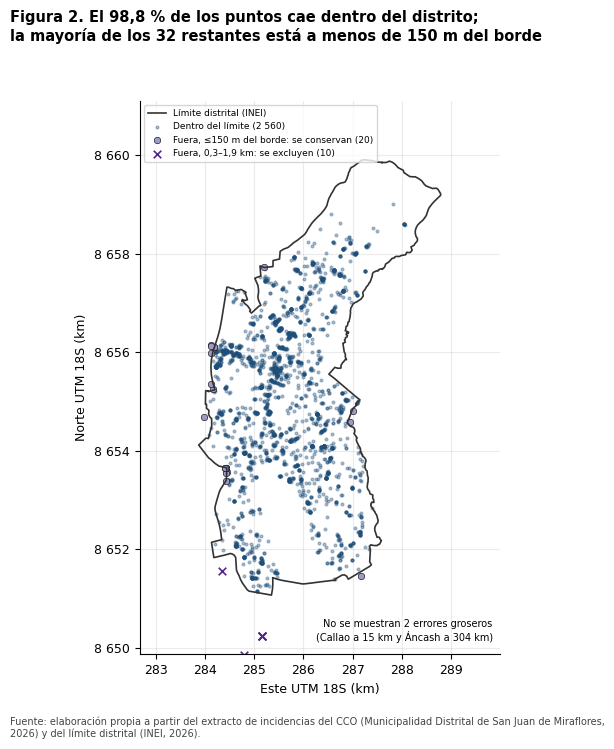

WindowsPath('C:/Users/Ghino/Desktop/prototipo-practicas-pre/02_documentacion/02_analisis/figuras/fig02_puntos_fuera_limite.png')

In [5]:
fig, ax = plt.subplots(figsize=(6.2, 7.5))
x_lim, y_lim = poligono.exterior.xy
ax.plot(np.array(x_lim) / 1000, np.array(y_lim) / 1000, color="#333333", lw=1.2, label="Límite distrital (INEI)")
dentro = df[df.dist_limite_m == 0]
ax.scatter(dentro.x_utm / 1000, dentro.y_utm / 1000, s=4, color=AZUL, alpha=0.35, label=f"Dentro del límite ({fmt(len(dentro))})")
b = df[(df.dist_limite_m > 0) & (df.dist_limite_m <= TOLERANCIA_BORDE_M)]
ax.scatter(b.x_utm / 1000, b.y_utm / 1000, s=22, color="#9E9AC8", edgecolor="k", lw=0.4,
           label=f"Fuera, ≤150 m del borde: se conservan ({fmt(len(b))})")
l = df[(df.dist_limite_m > TOLERANCIA_BORDE_M) & (df.dist_limite_m <= 10_000)]
ax.scatter(l.x_utm / 1000, l.y_utm / 1000, s=30, marker="x", color="#54278F", lw=1.2,
           label=f"Fuera, 0,3–1,9 km: se excluyen ({fmt(len(l))})")
ax.set_xlim(poligono.bounds[0] / 1000 - 1.2, poligono.bounds[2] / 1000 + 1.2)
ax.set_ylim(poligono.bounds[1] / 1000 - 1.2, poligono.bounds[3] / 1000 + 1.2)
ax.set_aspect("equal")
ax.set_xlabel("Este UTM 18S (km)"); ax.set_ylabel("Norte UTM 18S (km)")
eje_es(ax, "x", 0); eje_es(ax, "y", 0)
ax.legend(loc="upper left", fontsize=6.5, frameon=True)
ax.text(0.98, 0.02, f"No se muestran {n_groseros} errores groseros\n(Callao a 15 km y Áncash a 304 km)",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=7)
guardar_figura(fig, "fig02_puntos_fuera_limite.png", 2,
               "El 98,8 % de los puntos cae dentro del distrito;\nla mayoría de los 32 restantes está a menos de 150 m del borde",
               FUENTE_CCO_LIMITE)

## 4. Consistencia hora ↔ turno (corte horario observado)

In [6]:
df["hora_num"] = pd.to_datetime(df.hora, format="%H:%M:%S").dt.hour
df["minutos"] = pd.to_datetime(df.hora, format="%H:%M:%S").dt.hour * 60 + pd.to_datetime(df.hora, format="%H:%M:%S").dt.minute
cortes = {}
for t in TURNOS:
    m = df.loc[df.turno == t, "minutos"]
    if t == "Noche":
        tarde_noche = m[m >= 12 * 60]; madrugada = m[m < 12 * 60]
        cortes[t] = f"{tarde_noche.min() // 60:02d}:{tarde_noche.min() % 60:02d}–23:59 y 00:00–{madrugada.max() // 60:02d}:{madrugada.max() % 60:02d}"
    else:
        cortes[t] = f"{m.min() // 60:02d}:{m.min() % 60:02d}–{m.max() // 60:02d}:{m.max() % 60:02d}"
print("Rango horario observado por turno:", cortes)
regla = np.select([(df.hora_num >= 6) & (df.hora_num < 14), (df.hora_num >= 14) & (df.hora_num < 22)], ["Mañana", "Tarde"], "Noche")
inconsistentes = int((regla != df.turno).sum())
print(f"Registros cuyo turno no coincide con la regla 06–14 / 14–22 / 22–06: {inconsistentes}")
print("Nota: el turno Noche de una fecha agrupa 00:00–05:59 y 22:00–23:59 de ese mismo día calendario (fecha de registro).")
metricas.update(turno_inconsistente=inconsistentes, cortes_turno=cortes)

Rango horario observado por turno: {'Mañana': '06:06–13:59', 'Tarde': '14:10–21:59', 'Noche': '22:08–23:59 y 00:00–05:59'}
Registros cuyo turno no coincide con la regla 06–14 / 14–22 / 22–06: 0
Nota: el turno Noche de una fecha agrupa 00:00–05:59 y 22:00–23:59 de ese mismo día calendario (fecha de registro).


## 5. Sector y zona faltantes

In [7]:
df["sin_sector"] = df.sector.isna()
print(f"Sin sector: {df.sin_sector.sum()} ({pct(df.sin_sector.mean() * 100)}); sin zona: {df.zona.isna().sum()} ({pct(df.zona.isna().mean() * 100)})")
print((df.groupby("canal_reporte").sin_sector.agg(["sum", "mean"]).assign(mean=lambda t: (t["mean"] * 100).round(1))
       .rename(columns={"sum": "sin_sector", "mean": "pct"})).to_string())
print("Sin sector por zona:\n", df.groupby(df.zona.fillna("(sin zona)")).sin_sector.mean().mul(100).round(1).to_string())
print("Por eso la ubicación se toma de las coordenadas y el sector queda solo como referencia descriptiva.")
metricas.update(sin_sector=int(df.sin_sector.sum()), sin_zona=int(df.zona.isna().sum()))

Sin sector: 543 (20,9 %); sin zona: 312 (12,0 %)
                     sin_sector    pct
canal_reporte                         
CAMARAS CECOP               385   19.9
DESPACHADOR TETRA             0    0.0
FISCALIZACION                 0    0.0
JEFE DE OPERACIONES           1  100.0
LLAMDA TELEFONICA            77   24.2
OTROS                         2   16.7
WHATSAPP                     78   24.2
Sin sector por zona:
 zona
(sin zona)          100.0
LADERAS DE VILLA     94.1
MATEO PUMACAHUA      98.3
PAMPLONA I            0.0
PAMPLONA II           0.0
SAGITARIO           100.0
SAN JUAN              0.1
Por eso la ubicación se toma de las coordenadas y el sector queda solo como referencia descriptiva.


## 6. Catálogo de tipos y subtipos; normalización
Se crean etiquetas cortas (`tipo_corto`) y se corrigen erratas evidentes en copias normalizadas (`subtipo_norm`, `canal_norm`);
las columnas originales se conservan.

In [8]:
TIPO_CORTO = {
    "EMISION DE ALERTAS TEMPRANAS EN APOYO A LA PNP, EN ACTIVIDADES PRESUNTAMENTE DELICTIVAS": "Presuntamente delictivas",
    "EMISION DE ALERTAS TEMPRANAS EN APOYO A LA PNP EN PRESUNTAS FALTAS": "Presuntas faltas",
    "EMISION DE ALERTAS TEMPRANAS EN APOYO A LA PNP Y OTRAS GERENCIAS, EN PRESUNTAS INFRACCIONES": "Presuntas infracciones",
    "EMISION DE ALERTAS TEMPRANAS EN DESASTRES, INFRAESTRUCTURA, SERVICIOS Y ESPACIOS PÚBLICOS AFECTADOS Y EN RIESGO": "Infraestructura y riesgo",
    "OPERATIVOS": "Operativos",
    "AYUDA Y APOYO A PERSONAS Y ENTIDADES": "Ayuda y apoyo",
    "ACONTECIMIENTOS ESPECIALES": "Acontecimientos especiales",
}
assert set(df.tipo) == set(TIPO_CORTO), set(df.tipo) - set(TIPO_CORTO)
df["tipo_corto"] = df.tipo.map(TIPO_CORTO)
ERRATAS_SUBTIPO = {"PREUNTOS ": "PRESUNTOS ", "CONTRA CONTRA ": "CONTRA ", "ACTIV.CONTRA": "ACTIV. CONTRA"}
df["subtipo_norm"] = df.subtipo
for mal, bien in ERRATAS_SUBTIPO.items():
    df["subtipo_norm"] = df.subtipo_norm.str.replace(mal, bien, regex=False)
df["canal_norm"] = df.canal_reporte.replace({"LLAMDA TELEFONICA": "LLAMADA TELEFONICA"})
n_subtipo_corregido = int((df.subtipo_norm != df.subtipo).sum())
n_canal_corregido = int((df.canal_norm != df.canal_reporte).sum())
catalogo = df.groupby(["tipo_corto", "subtipo_norm"]).size().rename("registros").reset_index()
print(catalogo.to_string())
print(f"Tipos: {df.tipo.nunique()} · subtipos: {df.subtipo.nunique()} (normalizados: {df.subtipo_norm.nunique()}) · modalidades: {df.modalidad.nunique()}")
print(f"Filas con subtipo corregido: {n_subtipo_corregido}; con canal corregido: {n_canal_corregido}")
metricas.update(n_tipos=int(df.tipo.nunique()), n_subtipos=int(df.subtipo.nunique()),
                subtipo_corregido=n_subtipo_corregido, canal_corregido=n_canal_corregido,
                registros_por_tipo={k: int(v) for k, v in df.tipo_corto.value_counts().items()})

                    tipo_corto                                                     subtipo_norm  registros
0   Acontecimientos especiales                             PRESUNTOS ACONTECIMIENTOS ESPECIALES         10
1                Ayuda y apoyo                                          APOYO A OTRAS ENTIDADES          1
2                Ayuda y apoyo              APOYO A OTRAS GERENCIAS O AREAS DE LA MUNICIPALIDAD         72
3                Ayuda y apoyo                             AYUDA, AUXILIO Y RESCATE DE PERSONAS         40
4     Infraestructura y riesgo                                                        DESASTRES         29
5     Infraestructura y riesgo                                      ESPACIOS PÚBLICOS EN RIESGO         39
6     Infraestructura y riesgo                 INFRAESTRUCTURA Y SERVICIOS ESENCIALES AFECTADOS        197
7                   Operativos                                               OPERATIVO ESPECIAL         18
8                   Operativos       

## 7. Ubigeo
La fuente publica `UBIGEO = 150141` (Surquillo en INEI/SIDPOL); el canónico ya usa `150133` (SJM). Se verifica que se lea como texto de 6 caracteres.

In [9]:
assert df.ubigeo_inei.eq("150133").all()
print("ubigeo_inei = '150133' en el 100 % de filas (texto, 6 caracteres). Ubigeo de la fuente: 150141 (no se usa).")

ubigeo_inei = '150133' en el 100 % de filas (texto, 6 caracteres). Ubigeo de la fuente: 150141 (no se usa).


## 8. Cobertura temporal: arranque y cambio de nivel
El alcance señala ~84 registros/día en mayo y ~125 en junio. Se prueba si el cambio se explica por el canal de reporte
(cámaras del CECOP frente a WhatsApp/llamadas de contribuyentes) y por el tipo de reportante.

In [10]:
df["fecha_dt"] = pd.to_datetime(df.fecha)
diario = df.groupby("fecha").size()
print("Registros/día — mayo (16 días):", fmt(diario[diario.index < "2026-06-01"].mean(), 1),
      "· junio (10 días):", fmt(diario[diario.index >= "2026-06-01"].mean(), 1))
print("Turnos con registros por día en el arranque:")
arr = df[df.fecha <= "2026-05-22"].groupby(["fecha", "turno"]).size().unstack(fill_value=0)[TURNOS]
print(arr.to_string())
media_arranque = diario[diario.index <= FIN_ARRANQUE].mean()
media_estable_mayo = diario[(diario.index >= INICIO_ESTABLE) & (diario.index <= "2026-05-31")].mean()
media_estable_junio = diario[(diario.index >= "2026-06-01") & (diario.index <= FIN_ESTABLE)].mean()
print(f"Arranque 16–21 may: {fmt(media_arranque, 1)}/día · 22–31 may: {fmt(media_estable_mayo, 1)}/día · 1–8 jun: {fmt(media_estable_junio, 1)}/día")
metricas.update(media_mayo=round(diario[diario.index < "2026-06-01"].mean(), 1), media_junio=round(diario[diario.index >= "2026-06-01"].mean(), 1),
                media_arranque=round(media_arranque, 1), media_estable_mayo=round(media_estable_mayo, 1),
                media_estable_junio=round(media_estable_junio, 1),
                noche_arranque=int(arr.loc[arr.index <= "2026-05-20", "Noche"].sum()))

Registros/día — mayo (16 días): 83,7 · junio (10 días): 125,3
Turnos con registros por día en el arranque:
turno       Mañana  Tarde  Noche
fecha                           
2026-05-16       1      3      0
2026-05-17      27      2      0
2026-05-18      20      5      0
2026-05-19      17      6      0
2026-05-20      33     11      0
2026-05-21      40     16     11
2026-05-22      44     20     37
Arranque 16–21 may: 32,0/día · 22–31 may: 114,7/día · 1–8 jun: 133,1/día


Registros por día según canal:
                   A: 16–21 may (arranque, 6 d)  B: 22–28 may (7 d)  C: 29 may–4 jun (7 d)  cambio_B_a_C_%
canal_grupo                                                                                              
Cámaras CECOP                             29.5                69.9                   98.4            40.9
WhatsApp/llamada                           2.2                27.9                   31.3            12.3
Otros                                      0.3                 1.0                    1.3            28.6
TOTAL                                     32.0                98.7                  131.0            32.7

Registros por día según tipo de reportante:
                                A: 16–21 may (arranque, 6 d)  B: 22–28 may (7 d)  C: 29 may–4 jun (7 d)  cambio_B_a_C_%
tipo_reportante                                                                                                       
AGENTE DE SEGURIDAD EXTERNO                     

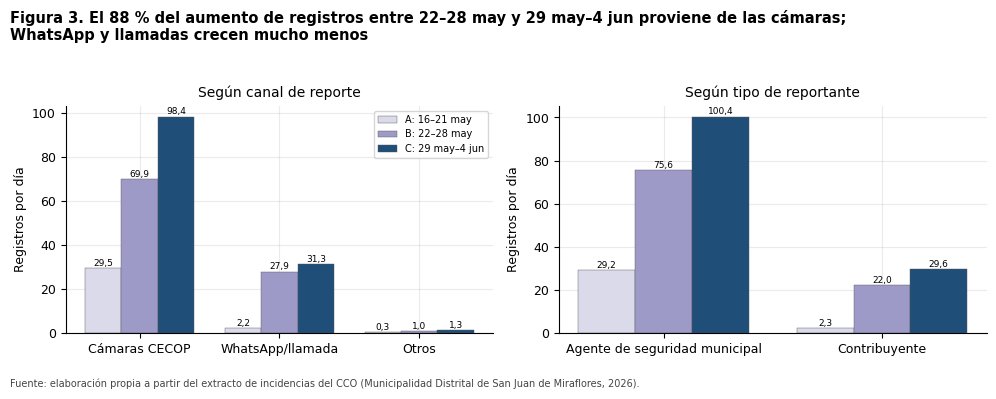

WindowsPath('C:/Users/Ghino/Desktop/prototipo-practicas-pre/02_documentacion/02_analisis/figuras/fig03_cobertura_canal_reportante.png')

In [11]:
# Bloques de 7 días dentro de la ventana estable (sin arranque ni días censurados) + arranque como referencia
bloques = {
    "A: 16–21 may (arranque, 6 d)": ("2026-05-16", "2026-05-21"),
    "B: 22–28 may (7 d)": ("2026-05-22", "2026-05-28"),
    "C: 29 may–4 jun (7 d)": ("2026-05-29", "2026-06-04"),
}
def por_dia(columna):
    filas = {}
    for nombre, (i, f) in bloques.items():
        sub = df[(df.fecha >= i) & (df.fecha <= f)]
        dias = (pd.Timestamp(f) - pd.Timestamp(i)).days + 1
        filas[nombre] = sub[columna].value_counts() / dias
    t = pd.DataFrame(filas).fillna(0)
    t["total_por_dia"] = 0
    t = t.drop(columns="total_por_dia")
    t.loc["TOTAL"] = t.sum()
    t["cambio_B_a_C_%"] = ((t.iloc[:, 2] / t.iloc[:, 1] - 1) * 100).round(1)
    return t.round(1)

df["canal_grupo"] = np.where(df.canal_reporte == "CAMARAS CECOP", "Cámaras CECOP",
                     np.where(df.canal_norm.isin(["WHATSAPP", "LLAMADA TELEFONICA"]), "WhatsApp/llamada", "Otros"))
t_canal = por_dia("canal_grupo")
t_rep = por_dia("tipo_reportante")
print("Registros por día según canal:\n", t_canal.to_string())
print("\nRegistros por día según tipo de reportante:\n", t_rep.to_string())
t_tipo = por_dia("tipo_corto")
print("\nRegistros por día según tipo:\n", t_tipo.to_string())
pct_camaras = (df.canal_reporte == "CAMARAS CECOP").mean() * 100
pct_agente = (df.tipo_reportante == "AGENTE DE SEGURIDAD MUNICIPAL").mean() * 100
pct_delictivas = (df.tipo_corto == "Presuntamente delictivas").mean() * 100
print(f"Sesgo de registro (2 592 registros): cámaras CECOP {fmt(pct_camaras, 1)} % · reporta un agente municipal {fmt(pct_agente, 1)} % · "
      f"presuntamente delictivas {fmt(pct_delictivas, 1)} %")
metricas.update(pct_camaras=round(pct_camaras, 1), pct_agente_municipal=round(pct_agente, 1), pct_delictivas=round(pct_delictivas, 1))
camaras_share = df.groupby(df.fecha <= FIN_ARRANQUE).canal_reporte.apply(lambda s: (s == "CAMARAS CECOP").mean() * 100)
print(f"\n% cámaras en el arranque: {fmt(camaras_share[True], 1)} % · en el resto: {fmt(camaras_share[False], 1)} %")
metricas["cobertura_canal"] = {k: {c: float(v) for c, v in fila.items()} for k, fila in t_canal.T.to_dict().items()}
metricas["cambio_B_C_total"] = float(t_canal.loc["TOTAL", "cambio_B_a_C_%"])
metricas["cambio_B_C_camaras"] = float(t_canal.loc["Cámaras CECOP", "cambio_B_a_C_%"])
metricas["cambio_B_C_whatsapp_llamada"] = float(t_canal.loc["WhatsApp/llamada", "cambio_B_a_C_%"])
metricas["cambio_B_C_contribuyente"] = float(t_rep.loc["CONTRIBUYENTE", "cambio_B_a_C_%"])
metricas["cambio_B_C_agente_municipal"] = float(t_rep.loc["AGENTE DE SEGURIDAD MUNICIPAL", "cambio_B_a_C_%"])
aporte_camaras = ((t_canal.loc["Cámaras CECOP"].iloc[2] - t_canal.loc["Cámaras CECOP"].iloc[1])
                  / (t_canal.loc["TOTAL"].iloc[2] - t_canal.loc["TOTAL"].iloc[1]) * 100)
print(f"Parte del aumento B→C aportada por cámaras: {fmt(aporte_camaras, 1)} %")
metricas["aporte_camaras_aumento_pct"] = round(float(aporte_camaras), 1)
metricas["arranque_por_dia_camaras"] =float(t_canal.loc["Cámaras CECOP"].iloc[0])
metricas["arranque_por_dia_whatsapp_llamada"] = float(t_canal.loc["WhatsApp/llamada"].iloc[0])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.9))
grupos = ["Cámaras CECOP", "WhatsApp/llamada", "Otros"]
xb = np.arange(3); ancho = 0.26
for k, (nombre, color) in enumerate(zip(t_canal.columns[:3], ["#DADAEB", "#9E9AC8", AZUL])):
    vals = t_canal.loc[grupos, nombre].values
    a1.bar(xb + (k - 1) * ancho, vals, ancho, color=color, label=nombre.split(" (")[0], edgecolor="#555555", lw=0.3)
    for x_, v in zip(xb + (k - 1) * ancho, vals):
        a1.text(x_, v + 1, fmt(v, 1), ha="center", fontsize=6.5)
a1.set_xticks(xb); a1.set_xticklabels(grupos); a1.set_ylabel("Registros por día"); a1.set_title("Según canal de reporte")
a1.legend(fontsize=7); eje_es(a1, "y", 0)
reps = ["AGENTE DE SEGURIDAD MUNICIPAL", "CONTRIBUYENTE"]
for k, (nombre, color) in enumerate(zip(t_rep.columns[:3], ["#DADAEB", "#9E9AC8", AZUL])):
    vals = t_rep.loc[reps, nombre].values
    a2.bar(np.arange(2) + (k - 1) * ancho, vals, ancho, color=color, edgecolor="#555555", lw=0.3)
    for x_, v in zip(np.arange(2) + (k - 1) * ancho, vals):
        a2.text(x_, v + 1, fmt(v, 1), ha="center", fontsize=6.5)
a2.set_xticks(np.arange(2)); a2.set_xticklabels(["Agente de seguridad municipal", "Contribuyente"])
a2.set_ylabel("Registros por día"); a2.set_title("Según tipo de reportante"); eje_es(a2, "y", 0)
guardar_figura(fig, "fig03_cobertura_canal_reportante.png", 3,
               f"El {fmt(aporte_camaras, 0)} % del aumento de registros entre 22–28 may y 29 may–4 jun proviene de las cámaras;\n"
               "WhatsApp y llamadas crecen mucho menos")

## 9. Censura a la derecha (solo se publican incidencias cerradas)
Se usa `tiempo_respuesta_min` **[POST]** únicamente para medir la censura del registro.

In [12]:
cierre = pd.to_datetime(df.fecha_hora_cierre.str[:19])
corte_obs = cierre.max()
mediana_auto = df.loc[(df.estado_final == "No atendida") & (df.tiempo_respuesta_min > 1380), "tiempo_respuesta_min"].median()
limite_censura = corte_obs - pd.Timedelta(minutes=float(mediana_auto))
print(f"Último cierre observado (≈ momento del corte): {corte_obs} · mediana del cierre automático: {mediana_auto:.0f} min")
print(f"=> las incidencias registradas después de ≈ {limite_censura:%Y-%m-%d %H:%M} que se cierran automáticamente aún no estaban cerradas y faltan.")
dia = df.groupby("fecha").agg(registros=("id_incidencia", "size"),
                              pct_cierre_23h=("tiempo_respuesta_min", lambda s: round((s > 1380).mean() * 100, 1)))
print(dia.tail(6).to_string())
ult = df[df.fecha.isin(["2026-06-08", "2026-06-09", "2026-06-10"])].groupby(["fecha", "turno"]).size().unstack(fill_value=0)[TURNOS]
ref = df[(df.fecha >= INICIO_ESTABLE) & (df.fecha <= "2026-06-08")].groupby(["fecha", "turno"]).size().unstack(fill_value=0)[TURNOS].mean().round(1)
print("Registros por turno en los últimos días:\n", ult.to_string(), "\nMedia 22 may–8 jun:\n", ref.to_string())
h_0609 = df[(df.fecha == "2026-06-09")].hora_num.value_counts().reindex(range(24), fill_value=0)
print("09 jun, registros entre 22:00 y 23:59:", int(h_0609[22:].sum()), "(media 22 may–8 jun:",
      fmt(df[(df.fecha >= INICIO_ESTABLE) & (df.fecha <= "2026-06-08") & (df.hora_num >= 22)].groupby("fecha").size().mean(), 1), ")")
max_resp = df.tiempo_respuesta_min.quantile(0.99)
print(f"P99 del tiempo de respuesta: {max_resp:.0f} min -> un registro del 08 jun a las 23:59 se cierra antes de "
      f"{(pd.Timestamp('2026-06-08 23:59') + pd.Timedelta(minutes=float(max_resp))):%Y-%m-%d %H:%M}, antes del corte: el 08 jun está completo.")
metricas.update(corte_observado=str(corte_obs), mediana_cierre_auto_min=float(mediana_auto), limite_censura=str(limite_censura),
                registros_0609=int(dia.loc["2026-06-09", "registros"]), registros_0610=int(dia.loc["2026-06-10", "registros"]),
                pct_cierre23_0609=float(dia.loc["2026-06-09", "pct_cierre_23h"]), pct_cierre23_0610=float(dia.loc["2026-06-10", "pct_cierre_23h"]),
                tarde_0609=int(ult.loc["2026-06-09", "Tarde"]), noche_0609=int(ult.loc["2026-06-09", "Noche"]),
                media_tarde=float(ref["Tarde"]), media_noche=float(ref["Noche"]),
                pct_cierre23_rango_estable=[float(dia.loc[INICIO_ESTABLE:"2026-06-08", "pct_cierre_23h"].min()),
                                            float(dia.loc[INICIO_ESTABLE:"2026-06-08", "pct_cierre_23h"].max())])

Último cierre observado (≈ momento del corte): 2026-06-10 15:09:00 · mediana del cierre automático: 1443 min
=> las incidencias registradas después de ≈ 2026-06-09 15:06 que se cierran automáticamente aún no estaban cerradas y faltan.
            registros  pct_cierre_23h
fecha                                
2026-06-05        152            78.3
2026-06-06        117            83.8
2026-06-07        187            71.1
2026-06-08        148            71.6
2026-06-09        108            61.1
2026-06-10         80             0.0
Registros por turno en los últimos días:
 turno       Mañana  Tarde  Noche
fecha                           
2026-06-08      55     52     41
2026-06-09      65     23     20
2026-06-10      80      0      0 
Media 22 may–8 jun:
 turno
Mañana    52.2
Tarde     30.6
Noche     40.2
09 jun, registros entre 22:00 y 23:59: 0 (media 22 may–8 jun: 13,3 )
P99 del tiempo de respuesta: 1522 min -> un registro del 08 jun a las 23:59 se cierra antes de 2026-06-10 01:21,

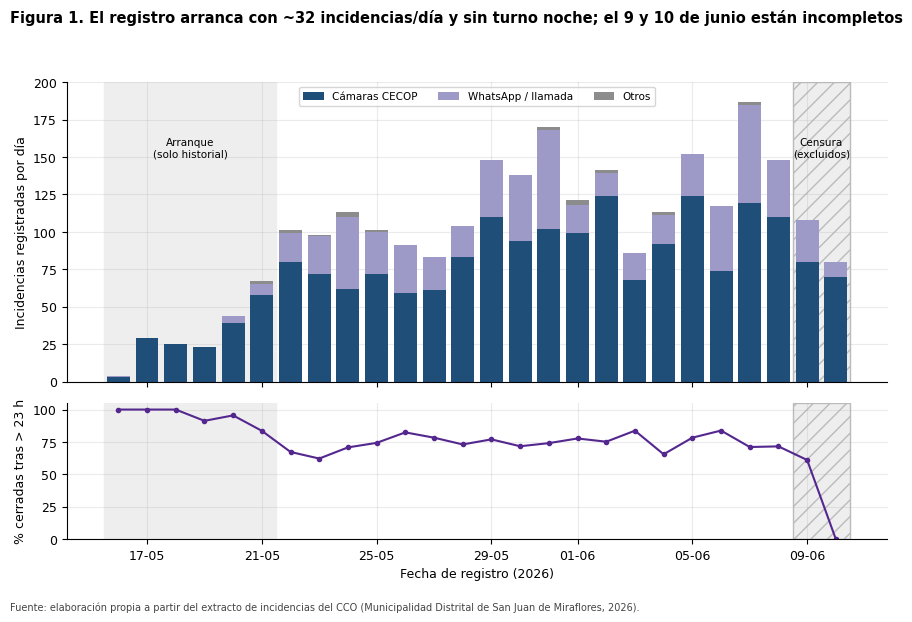

WindowsPath('C:/Users/Ghino/Desktop/prototipo-practicas-pre/02_documentacion/02_analisis/figuras/fig01_cobertura_diaria_canal.png')

In [13]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
pv = df.groupby(["fecha_dt", "canal_grupo"]).size().unstack(fill_value=0)[["Cámaras CECOP", "WhatsApp/llamada", "Otros"]]
fondo = pv.index
ax1.bar(pv.index, pv["Cámaras CECOP"], color=AZUL, label="Cámaras CECOP", width=0.8)
ax1.bar(pv.index, pv["WhatsApp/llamada"], bottom=pv["Cámaras CECOP"], color="#9E9AC8", label="WhatsApp / llamada", width=0.8)
ax1.bar(pv.index, pv["Otros"], bottom=pv["Cámaras CECOP"] + pv["WhatsApp/llamada"], color=GRIS, label="Otros", width=0.8)
for ax in (ax1, ax2):
    ax.axvspan(pd.Timestamp("2026-05-15 12:00"), pd.Timestamp("2026-05-21 12:00"), color="#EEEEEE", zorder=0)
    ax.axvspan(pd.Timestamp("2026-06-08 12:00"), pd.Timestamp("2026-06-10 12:00"), color="#EEEEEE", hatch="//", zorder=0, ec="#BBBBBB")
ax1.text(pd.Timestamp("2026-05-18 12:00"), 150, "Arranque\n(solo historial)", ha="center", fontsize=7.5)
ax1.text(pd.Timestamp("2026-06-09 12:00"), 150, "Censura\n(excluidos)", ha="center", fontsize=7.5)
ax1.set_ylabel("Incidencias registradas por día"); ax1.set_ylim(0, 200); ax1.legend(loc="upper center", fontsize=7.5, ncol=3)
ax2.plot(dia.index.map(pd.Timestamp), dia.pct_cierre_23h, marker="o", ms=3, color="#54278F")
ax2.set_ylabel("% cerradas tras > 23 h"); ax2.set_ylim(0, 105)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m")); ax2.set_xlabel("Fecha de registro (2026)")
guardar_figura(fig, "fig01_cobertura_diaria_canal.png", 1,
               "El registro arranca con ~32 incidencias/día y sin turno noche; el 9 y 10 de junio están incompletos")

## 10. Reglas de limpieza y dataset limpio
Cada regla queda con su conteo en `metricas_calidad.json` y se documenta en `reglas_limpieza.md`.

In [14]:
reglas = []
n0 = len(df)
reglas.append({"id": "R1", "regla": "Leer id_incidencia, ubigeo_inei, zona y sector como texto", "filas_afectadas": 0, "accion": "tipado"})
excluir_espacial = df.dist_limite_m > TOLERANCIA_BORDE_M
reglas.append({"id": "R2", "regla": "Excluir puntos a más de 150 m del límite distrital", "filas_afectadas": int(excluir_espacial.sum()), "accion": "excluir"})
df["en_tolerancia_borde"] = (df.dist_limite_m > 0) & (df.dist_limite_m <= TOLERANCIA_BORDE_M)
reglas.append({"id": "R3", "regla": "Conservar puntos fuera del límite a ≤150 m (marcados en_tolerancia_borde)", "filas_afectadas": int(df.en_tolerancia_borde.sum()), "accion": "marcar"})
df["periodo"] = np.select([df.fecha <= FIN_ARRANQUE, df.fecha.isin(FECHAS_CENSURADAS)], ["arranque", "censurado"], "estable")
reglas.append({"id": "R4", "regla": "Marcar 16–21 may como 'arranque' (solo historial para rezagos)", "filas_afectadas": int(((df.periodo == "arranque") & ~excluir_espacial).sum()), "accion": "marcar"})
reglas.append({"id": "R5", "regla": "Marcar 9–10 jun como 'censurado' (fuera de la tabla de modelado)", "filas_afectadas": int(((df.periodo == "censurado") & ~excluir_espacial).sum()), "accion": "marcar"})
reglas.append({"id": "R6", "regla": "Etiqueta corta de tipo y corrección de erratas en subtipo/canal (copias normalizadas)",
               "filas_afectadas": int(n_subtipo_corregido + n_canal_corregido), "accion": "normalizar"})
reglas.append({"id": "R7", "regla": "Eliminar columnas [POST] (estado_final, fecha_hora_cierre, tiempo_respuesta_min) del dataset limpio", "filas_afectadas": 0, "accion": "eliminar columnas"})
reglas.append({"id": "R8", "regla": "Duplicados de ID o de contenido", "filas_afectadas": dup_id + dup_contenido, "accion": "ninguna (no hay)"})
reglas.append({"id": "R9", "regla": "Sector/zona vacíos se mantienen nulos; la ubicación se toma de las coordenadas", "filas_afectadas": int(df.sin_sector.sum()), "accion": "mantener"})

limpias = df.loc[~excluir_espacial].copy()
limpias["dia_semana"] = limpias.fecha_dt.dt.dayofweek
columnas = ["id_incidencia", "fuente_dataset", "distrito", "ubigeo_inei", "fecha", "hora", "fecha_hora", "hora_num", "dia_semana",
            "turno", "periodo", "tipo", "tipo_corto", "subtipo", "subtipo_norm", "modalidad", "zona", "sector",
            "lat", "lon", "x_utm", "y_utm", "dentro_distrito", "dist_limite_m", "en_tolerancia_borde",
            "canal_reporte", "canal_norm", "tipo_reportante", "direccion"]
limpias = limpias[columnas].sort_values(["fecha_hora", "id_incidencia"]).reset_index(drop=True)
limpias["x_utm"] = limpias.x_utm.round(2); limpias["y_utm"] = limpias.y_utm.round(2)
assert not ({"estado_final", "fecha_hora_cierre", "tiempo_respuesta_min"} & set(limpias.columns))
limpias.to_csv(DATOS / "incidencias_limpias.csv", index=False, encoding="utf-8")
print(pd.DataFrame(reglas).to_string(index=False))
print(f"\nDataset limpio: {len(limpias)} registros (de {n0}); por periodo:", limpias.periodo.value_counts().to_dict())
metricas.update(registros_limpios=int(len(limpias)), reglas=reglas,
                limpias_por_periodo={k: int(v) for k, v in limpias.periodo.value_counts().items()})
(DATOS / "metricas_calidad.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

id                                                                                               regla  filas_afectadas            accion
R1                                           Leer id_incidencia, ubigeo_inei, zona y sector como texto                0            tipado
R2                                                  Excluir puntos a más de 150 m del límite distrital               12           excluir
R3                           Conservar puntos fuera del límite a ≤150 m (marcados en_tolerancia_borde)               20            marcar
R4                                      Marcar 16–21 may como 'arranque' (solo historial para rezagos)              192            marcar
R5                                    Marcar 9–10 jun como 'censurado' (fuera de la tabla de modelado)              185            marcar
R6               Etiqueta corta de tipo y corrección de erratas en subtipo/canal (copias normalizadas)              359        normalizar
R7 Eliminar columnas [POST] (estad

4118

## Hallazgos

1. **Completitud y duplicados.** Fecha, hora, turno, tipo y coordenadas están completos; no hay ID duplicados ni duplicados de contenido
   (misma fecha-hora, coordenadas y modalidad). Solo faltan `sector` (20,9 %) y `zona` (12,0 %), así que la ubicación se toma de las coordenadas.
2. **Coordenadas.** 32 puntos caen fuera del límite INEI: 20 a ≤ 113 m del borde (se conservan con tolerancia de 150 m, hay un hueco natural
   hasta el siguiente punto a 287 m), 10 entre 0,3 y 1,9 km y 2 errores groseros (se excluyen 12 en total).
3. **Turno.** La regla 06–14 / 14–22 / 22–06 se cumple en el 100 %; el turno Noche de una fecha reúne la madrugada y las 22–24 h del mismo día calendario.
4. **Arranque (16–21 may).** ~32 registros/día y **ningún registro de turno Noche entre el 16 y el 20 de mayo**: es la puesta en marcha del
   registro, no una caída real. Se conserva solo como historial para los rezagos y no genera filas objetivo.
5. **Cambio de cobertura.** Tras el arranque, del bloque 22–28 may (98,7/día) al bloque 29 may–4 jun (131,0/día) el total sube 32,7 %.
   El **88 % del aumento proviene de las cámaras CECOP** (+40,9 %), mientras que WhatsApp/llamadas crece solo 12,3 %; sin embargo, los
   registros cuyo reportante es un contribuyente también suben (+34,4 %). La evidencia apunta sobre todo a un **cambio en el esfuerzo de
   registro por cámaras**, sin descartar un aumento real parcial: es **no concluyente**. En el arranque el patrón es inequívoco: 92 % cámaras
   y apenas 2,2 registros/día por WhatsApp/llamada (frente a ~28 después), es decir, canales todavía no incorporados.
   Recomendación: incluir variables de nivel global del distrito rezagadas (`distrito_lag1`, `distrito_media7`) para que el modelo pueda
   reescalar, y leer las diferencias entre periodos con cautela.
6. **Censura.** El corte se hizo el 10 jun hacia las 15:09 y el cierre automático tarda ~24 h: faltan las incidencias registradas desde
   ≈ las 15:00 del 9 jun que seguían abiertas. El 9 jun tiene la tarde y la noche mermadas (0 registros entre 22:00 y 23:59) y el 10 jun solo la mañana.
   **Se excluyen el 9 y el 10 de junio** de la tabla de modelado; el 8 de junio está completo.
7. **Sesgo de registro.** ~3/4 de los registros provienen de cámaras: los datos describen dónde mira el CCO, no la incidencia real.

Las cifras exactas de cada punto están en las salidas de arriba y en `datos/metricas_calidad.json`.